In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
data_dir = Path("data/raw")
files = list(data_dir.glob("*"))

if not files:
    raise FileNotFoundError(
        "No dataset found in data/raw. Download the data first."
    )
    
file_path = files[0]

if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path)
elif file_path.suffix.lower() in [".xlsx", ".xls"]:
    df = pd.read_excel(file_path)

else:
    raise ValueError(
        f"Unsupported file format: {file_path.suffix}"
    )

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(df.duplicated().sum())



Dataset shape:
(4046, 11)

Column names:
['Unnamed: 0', 'Country', 'Region', 'Market', 'Product', 'Date', 'Open', 'High', 'Low', 'Close', 'Currency']

First five rows:
   Unnamed: 0  Country          Region          Market Product        Date  \
0         NaN  Nigeria  Market Average  Market Average   beans  2007-01-01   
1         NaN  Nigeria  Market Average  Market Average   beans  2007-02-01   
2         NaN  Nigeria  Market Average  Market Average   beans  2007-03-01   
3         NaN  Nigeria  Market Average  Market Average   beans  2007-04-01   
4         NaN  Nigeria  Market Average  Market Average   beans  2007-05-01   

     Open    High     Low   Close Currency  
0  158.83  170.03  150.49  159.07      NGN  
1  160.50  171.06  150.72  171.06      NGN  
2  174.09  184.56  163.61  172.49      NGN  
3  174.90  186.54  164.80  186.54      NGN  
4  190.57  201.68  179.46  199.34      NGN  

Data types:
Unnamed: 0    float64
Country           str
Region            str
Market       

In [3]:
# 1. Load the original dataset
DATA_PATH = Path("data/raw/data.csv")
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

# 2. Remove empty export/index columns
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.str.startswith("Unnamed:")]

# 3. Parse dates and numeric columns
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in ["Open", "High", "Low", "Close"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 4. Remove rows missing essential forecasting information
df = df.dropna(subset=["Date", "Product", "Close"])

# 5. Select rice observations
rice = df.loc[df["Product"].str.lower() == "rice"].copy()
rice = rice.sort_values("Date")

# 6. Check for duplicate dates
rice = rice.drop_duplicates(subset=["Date"], keep="last")

# 7. Keep relevant columns
rice = rice[["Date", "Country", "Market", "Product", "Close", "Currency"]]

# 8. Save the cleaned dataset
output_path = OUTPUT_DIR / "rice_prices_clean.csv"
rice.to_csv(output_path, index=False)

In [4]:
print("Cleaned rice dataset saved to:", output_path)
print("\nNumber of rice observations:", len(rice))
print("\nDate range:", rice["Date"].min(), "to", rice["Date"].max())
print("\nSummary statistics:")
print(rice["Close"].describe())

Cleaned rice dataset saved to: data\processed\rice_prices_clean.csv

Number of rice observations: 238

Date range: 2007-01-01 00:00:00 to 2026-10-01 00:00:00

Summary statistics:
count     238.000000
mean     1709.100252
std      1785.007318
min       292.610000
25%       453.180000
50%      1081.310000
75%      1861.792500
max      6938.710000
Name: Close, dtype: float64


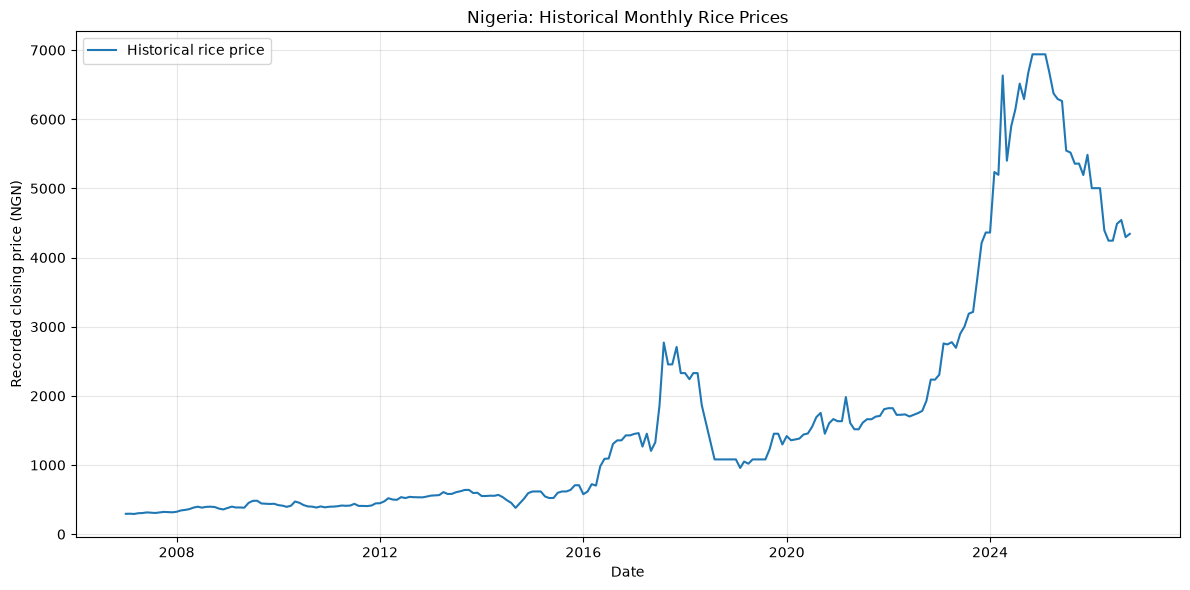

In [5]:
# 9. Plot historical prices
plt.figure(figsize=(12, 6))
plt.plot(rice["Date"], rice["Close"], label="Historical rice price")

plt.title("Nigeria: Historical Monthly Rice Prices")
plt.xlabel("Date")
plt.ylabel("Recorded closing price (NGN)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "rice_price_history.png", dpi=150)
plt.show()
